# Social Media Sentiment Analysis - EDA: Platform & Hashtag Analysis
**Dataset**: `sentiment_cleaned.csv`
**Purpose**: Conduct Exploratory Data Analysis (EDA) on **Platform-specific Sentiment Trends** and **Hashtag/Topic Trends vs User Engagement** for the Midterm Presentation.

## 1. Import Libraries & Load Cleaned Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# Load dataset
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/sentiment_cleaned.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the extracted repository with data/processed/sentiment_cleaned.csv present.')
OUT=ROOT/'generated/eda_platform_hashtags'
OUT.mkdir(parents=True,exist_ok=True)
df = pd.read_csv(ROOT/'data/processed/sentiment_cleaned.csv')
print(f"Dataset loaded successfully. Shape: {df.shape}")
df[['platform', 'sentiment', 'hashtags', 'likes', 'retweets', 'total_interactions']].head()

Dataset loaded successfully. Shape: (710, 26)


,platform,sentiment,hashtags,likes,retweets,total_interactions
0,Twitter,Positive,#Nature #Park,30,15,45
1,Twitter,Negative,#Traffic #Morning,10,5,15
2,Instagram,Positive,#Fitness #Workout,40,20,60
3,Facebook,Positive,#Travel #Adventure,15,8,23
4,Instagram,Neutral,#Cooking #Food,25,12,37


## 2. Platform-Specific Sentiment & Engagement Analysis
**Objective**: Compare sentiment distributions and user interactions across Facebook, Instagram, and Twitter.

Subset denominators: {'Facebook': 84, 'Instagram': 79, 'Twitter': 72} total: 235


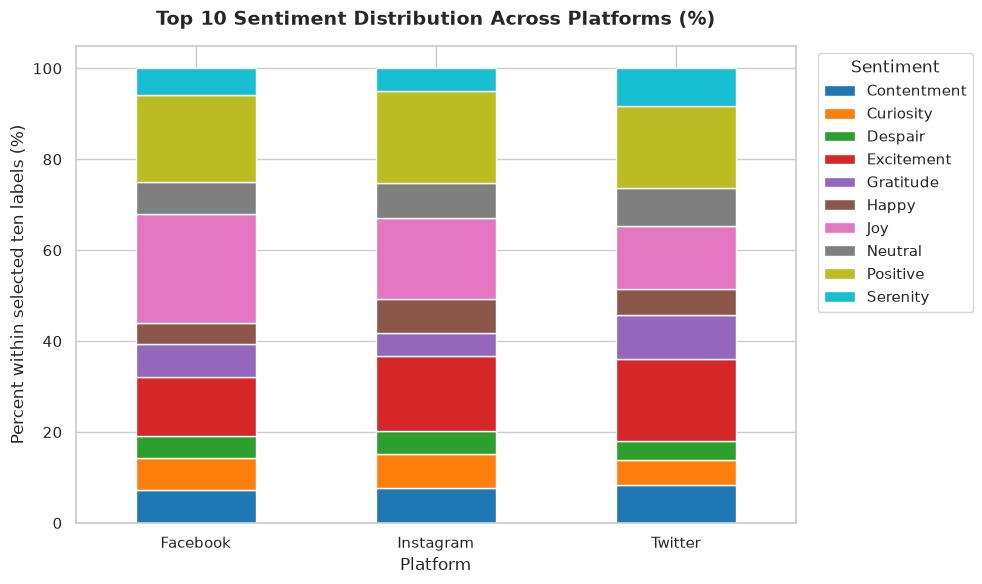

/var/folders/r2/lvmk1t_j7ts_5gld209c0c8r0000gn/T/ipykernel_39526/4118102491.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='platform', y='total_interactions', palette='Set2', errorbar=None)


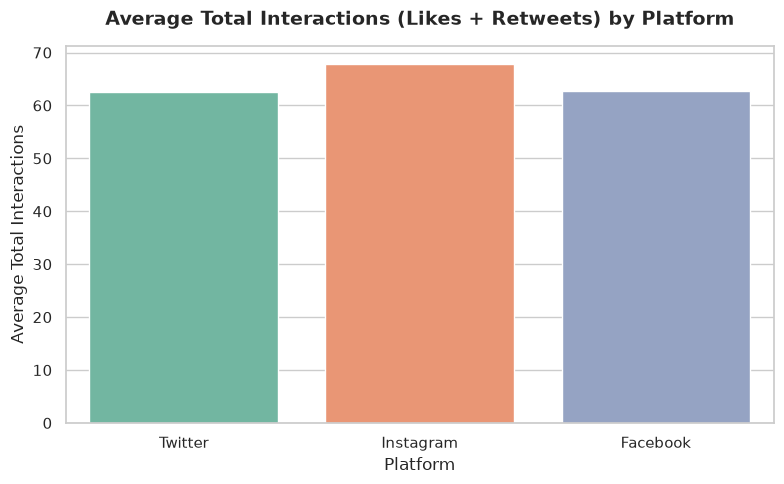

In [2]:
# 2.1 Top 10 Sentiment Distribution per Platform (%)
# Fixed selection reproduces the supplied figure despite the Despair/Nostalgia frequency tie.
top_10_sentiments = ['Contentment','Curiosity','Despair','Excitement','Gratitude','Happy','Joy','Neutral','Positive','Serenity']
df_top_sent = df[df['sentiment'].isin(top_10_sentiments)]

platform_sentiment_pct = pd.crosstab(df_top_sent['platform'], df_top_sent['sentiment'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 6))
platform_sentiment_pct.plot(kind='bar', stacked=True, ax=ax, colormap='tab10')
plt.title('Top 10 Sentiment Distribution Across Platforms (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Percent within selected ten labels (%)', fontsize=12)
print('Subset denominators:', df_top_sent.groupby('platform').size().to_dict(), 'total:', len(df_top_sent))
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT/'eda_platform_sentiment_distribution.png', dpi=300)
plt.show()

# 2.2 Average Total Interactions per Platform
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='platform', y='total_interactions', palette='Set2', errorbar=None)
plt.title('Average Total Interactions (Likes + Retweets) by Platform', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Platform', fontsize=12)
plt.ylabel('Average Total Interactions', fontsize=12)
plt.tight_layout()
plt.savefig(OUT/'eda_platform_interactions.png', dpi=300)
plt.show()

## 3. Hashtag & Topic Trends Analysis
**Objective**: Parse hashtag lists, find the most frequent hashtags, and describe their recorded interaction counts.

/var/folders/r2/lvmk1t_j7ts_5gld209c0c8r0000gn/T/ipykernel_39526/2538697911.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=hashtag_stats, x='frequency', y='parsed_hashtags', palette='Blues_r')


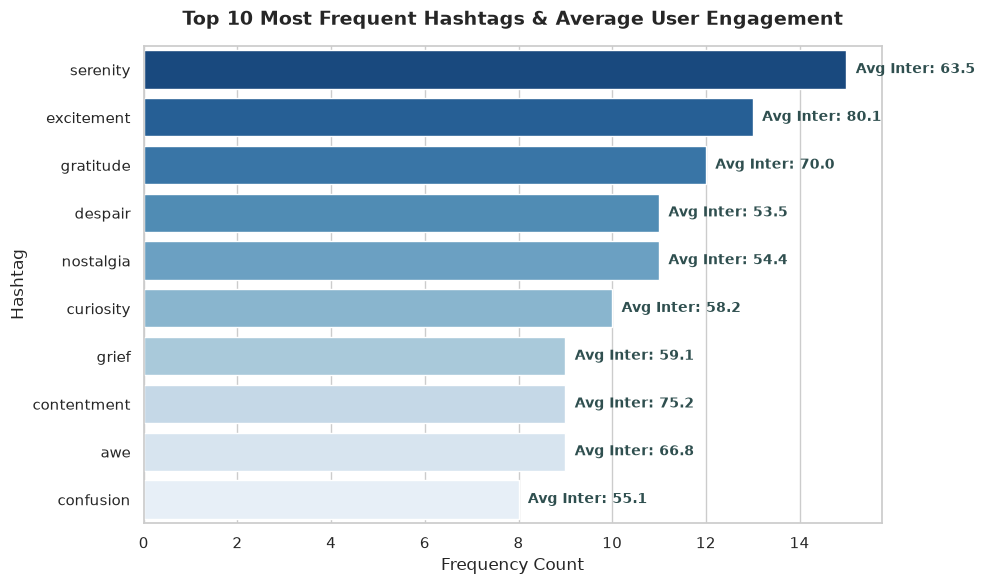

In [3]:
# 3.1 Unpack hashtag_list column
def parse_hashtags(x):
    try:
        return ast.literal_eval(x)
    except:
        return []

df['parsed_hashtags'] = df['hashtag_list'].apply(parse_hashtags)
exploded_df = df.explode('parsed_hashtags')
exploded_df = exploded_df[exploded_df['parsed_hashtags'].notna() & (exploded_df['parsed_hashtags'] != '')]

# 3.2 Aggregate Top 10 Hashtags by frequency and interaction
hashtag_stats = exploded_df.groupby('parsed_hashtags').agg(
    frequency=('parsed_hashtags', 'count'),
    avg_likes=('likes', 'mean'),
    avg_total_interactions=('total_interactions', 'mean')
).reset_index().sort_values(by='frequency', ascending=False).head(10)

# 3.3 Visualize Top 10 Hashtags
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=hashtag_stats, x='frequency', y='parsed_hashtags', palette='Blues_r')
plt.title('Top 10 Most Frequent Hashtags & Average User Engagement', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Frequency Count', fontsize=12)
plt.ylabel('Hashtag', fontsize=12)

for index, row in hashtag_stats.reset_index(drop=True).iterrows():
    ax.text(row['frequency'] + 0.2, index, f"Avg Inter: {row['avg_total_interactions']:.1f}", 
            va='center', fontsize=10, fontweight='bold', color='darkslategray')

plt.tight_layout()
plt.savefig(OUT/'eda_top_hashtags_engagement.png', dpi=300)
plt.show()

## 4 Key insights and limits
Instagram has a recorded mean of 67.9 interactions, Twitter 62.5, and Facebook 62.8. These are sample means, not exposure-normalized rates.

The platform sentiment chart uses only ten selected labels: Facebook n=84, Instagram n=79, Twitter n=72 (235 posts total). It does not show the complete platform mix. The selected labels are fixed to match the original figure when frequencies tie.

Serenity occurs in 15 posts and excitement in 13. The excitement group has a mean of about 80.1 interactions. Hashtag groups overlap. No statistical test or causal claim supports saying hashtags drive significantly higher engagement. No universal platform emotion preference is established.

Repository adaptation: paths and output directories are portable, and this interpretation replaces the original unsupported significance and platform-generalization statements. Original figures are preserved in reports/eda/figures. All input rows are unchanged.